# Operator motifs along a time course

This tutorial walks through the motif layer of the flow route (`scjdo2.flow_motifs`), one function at a time, on simulated data where the answer is known. It runs in under a minute on a laptop CPU. The same steps are in `examples/flow_motifs_tutorial.py`.

**The idea.** `sj.flow` gives every cell an operator $J$ (the local Jacobian of the drift). On its own, $J$ has no order: nothing links a day-2 cell's operator to those of the day-4 cells it becomes. The optimal-transport plan between sampling times does, and `sj.flow` now keeps it. Chaining operator **shapes** (archetypes) along the plan gives operator sequences.

| step | function | output |
|---|---|---|
| 1 | `sj.flow` | operator per cell; OT plan `obsp["flow_plan"]`; drift weights |
| 2 | `sj.flow_archetypes` | operator shapes, a label per cell |
| 3 | `sj.flow_transitions` | label → label per time pair vs a shuffle null (main readout) |
| 4 | `sj.flow_paths` | chains through the plan vs a Markov chain (robustness) |
| 5 | `sj.flow_integrate` | drift paths with the operator profile (pictures) |

> **Status.** New and not yet benchmarked: archetype stability across biological replicates has not been tested. Read results within one dataset.

In [1]:
import numpy as np, pandas as pd, anndata as ad
import matplotlib.pyplot as plt
import scjdo2 as sj
from scjdo2.plot import figure_flow_archetypes, figure_flow_transitions, figure_flow_groups
pd.set_option("display.width", 120)

## Test data: a pitchfork in time

Five sampling times. Cells move along PC1 and split into two arms along PC2 after day 2. So the truth is *approach* (days 0–1) → *branch point* (day 2) → *committed arms* (days 3–4), and a cell keeps its arm once it has split. Both arms hold half the cells at every time, because balanced transport would otherwise move any difference in arm size as cells switching arm.

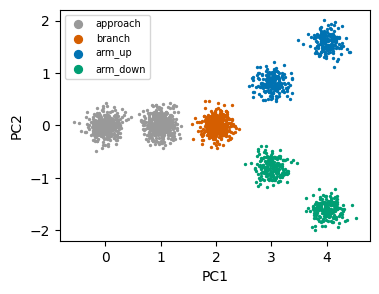

In [2]:
def pitchfork(n_per_time=400, seed=0):
    rng = np.random.default_rng(seed)
    z, t, lab = [], [], []
    for k in range(5):
        x = k + 0.15 * rng.standard_normal(n_per_time)
        arm = rng.permutation(np.repeat([-1.0, 1.0], n_per_time // 2))
        y = arm * max(k - 2, 0) * 0.8 + 0.15 * rng.standard_normal(n_per_time)
        z.append(np.column_stack([x, y, 0.1 * rng.standard_normal((n_per_time, 3))]))
        t.append(np.full(n_per_time, float(k)))
        lab.append(np.where(k < 2, "approach", np.where(k == 2, "branch", np.where(arm > 0, "arm_up", "arm_down"))))
    a = ad.AnnData(X=np.zeros((5 * n_per_time, 1), np.float32))
    a.obsm["X_pca"] = np.vstack(z).astype(np.float32)   # stands in for a PCA of log-normalised counts
    a.obs["day"] = np.concatenate(t)
    a.obs["stage"] = pd.Categorical(np.concatenate(lab), categories=["approach", "branch", "arm_up", "arm_down"])
    return a

adata = pitchfork()
fig, ax = plt.subplots(figsize=(4, 3))
for s, c in zip(adata.obs["stage"].cat.categories, ["0.6", "#d55e00", "#0072b2", "#009e73"]):
    m = (adata.obs["stage"] == s).to_numpy()
    ax.scatter(*adata.obsm["X_pca"][m, :2].T, s=2, color=c, label=s)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, markerscale=4); plt.show()

## 1. `sj.flow`: the operator, the plan and the drift

Entropic OT between consecutive times gives each cell a velocity; an MLP drift is fitted to those velocities; $J$ is its Jacobian at every cell. New: `keep_plan` (default 100) stores each cell's most likely destinations at the next time in `obsp["flow_plan"]` (each row sums to 1), and the drift weights go to `uns["flow"]["drift_weights"]`. Velocities and $\lambda_1$ are unchanged.

`plan_kept_mass_median` is how much of each row's mass the stored top-100 holds. The entropic plan is diffuse, so this is a truncation; `flow_transitions` does not use it by default.

In [3]:
sj.flow(adata, time_key="day", n_comps=5, device="cpu")
print(adata.uns["scjdo2"]["J"].shape, "operators; plan", adata.obsp["flow_plan"].shape, f"{adata.obsp['flow_plan'].nnz:,} entries")
adata.uns["flow"]["ot_pairs"][["from_time", "to_time", "solver", "plan_kept_mass_median"]]

(2000, 5, 5) operators; plan (2000, 2000) 160,000 entries


,from_time,to_time,solver,plan_kept_mass_median
0,0.0,1.0,dense,0.610161
1,1.0,2.0,dense,0.601210
2,2.0,3.0,dense,0.662488
3,3.0,4.0,dense,0.622625


$\lambda_1$ (largest real part of the eigenvalues of $J$) per group: positive where nearby cells spread apart (the branch point), negative where they converge (the arms). Read it per group: per-cell values vary between refits.

In [4]:
sj.flow_groups(adata, "stage")[["group", "n_cells", "frac_extrapolated", "median_lambda1", "ci_low", "ci_high"]]

,group,n_cells,frac_extrapolated,median_lambda1,ci_low,ci_high
0,branch,400,0.0,2.397192,2.358204,2.431896
1,approach,800,0.0,0.055428,0.033955,0.069017
2,arm_down,400,0.5,-0.101820,-0.116009,-0.081148
3,arm_up,400,0.5,-0.246755,-0.252712,-0.243195


## 2. `sj.flow_archetypes`: operator shapes

Each cell's $J$ is divided by its Frobenius norm (shape, not speed: the clock of a time course is arbitrary), then factorised by semi-NMF, $\tilde J_c \approx \sum_a W_{ca} H_a$ with $W \ge 0$. A cell's label is its largest weight. `n_archetypes="auto"` picks $K$ by held-out error (and warns if it picks the largest candidate); here we fix $K = 2$.

In [5]:
patterns = sj.flow_archetypes(adata, n_archetypes=2)
arch = adata.uns["flow"]["archetypes"]
print({n: round(float(r), 3) for n, r in zip(arch["names"], arch["eig_real"][:, 0])}, "<- leading Re(lambda) per archetype")
pd.crosstab(adata.obs["stage"], adata.obs["flow_archetype"])

{'A1': -0.047, 'A2': 0.865} <- leading Re(lambda) per archetype


flow_archetype,A1,A2
stage,,
approach,483,317
branch,3,397
arm_up,400,0
arm_down,360,40


**Reading an archetype** (`figure_flow_archetypes`). Top: the eigenvalues on the complex plane. A positive real part (orange) is a direction along which cells spread apart; negative (blue), one they converge along. A non-zero imaginary part is local rotation, in radians per unit of `time_key`; it is not a calibrated clock and has not been validated as a cycle. Bottom: the matrix. Asymmetry across the diagonal is the non-normal part (stretching, transient gain), which the eigenvalues do not show. Flow $J$ carries direction from time itself; `sj.orient` is only for the energy operator.

Here A2 is the spreading shape (all branch-point cells) and A1 the converging one (the arms).

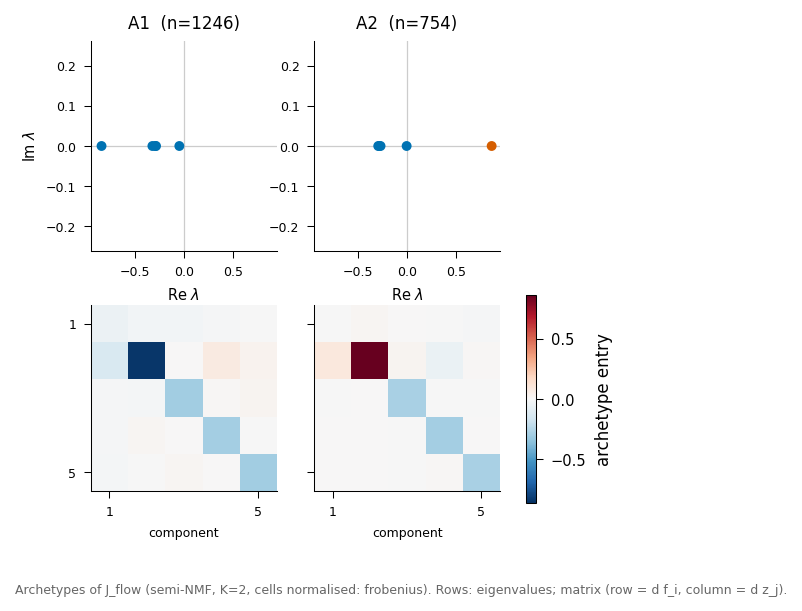

In [6]:
fig = figure_flow_archetypes(adata); plt.show()

## 3. `sj.flow_transitions`: the main readout

For each pair of consecutive times: the mass cells labelled $a$ send to cells labelled $b$, and `prob` $= P(b\mid a)$. The null shuffles source labels among the cells of the source time (label sizes and target composition kept), so `p_enriched` asks whether a cell's label predicts where it goes. It re-runs the transport with the stored settings (checked against the stored velocities) and uses the **full** plan, so nothing is truncated.

Any `obs` column can be the labels. With `stage`: branch cells split 50/50 into the two arms, and each arm stays itself ($P = 1$, far above the null's 0.5). Where a source time has a single label (days 0–2) there is nothing to shuffle, and the null columns are NaN.

In [7]:
tab = sj.flow_transitions(adata, labels="stage", n_perm=500)
tab[tab["prob"] > 0.05][["from_time", "to_time", "from_label", "to_label", "n_from", "prob", "expected_prob", "z", "p_enriched", "to_extrapolated"]].round(3)

,from_time,to_time,from_label,to_label,n_from,prob,expected_prob,z,p_enriched,to_extrapolated
0,0.0,1.0,approach,approach,400,1.0,NaN,NaN,NaN,False
5,1.0,2.0,approach,branch,400,1.0,NaN,NaN,NaN,False
10,2.0,3.0,branch,arm_up,400,0.5,NaN,NaN,NaN,False
11,2.0,3.0,branch,arm_down,400,0.5,NaN,NaN,NaN,False
14,3.0,4.0,arm_up,arm_up,200,1.0,0.501,20.147,0.002,True
19,3.0,4.0,arm_down,arm_down,200,1.0,0.501,20.147,0.002,True


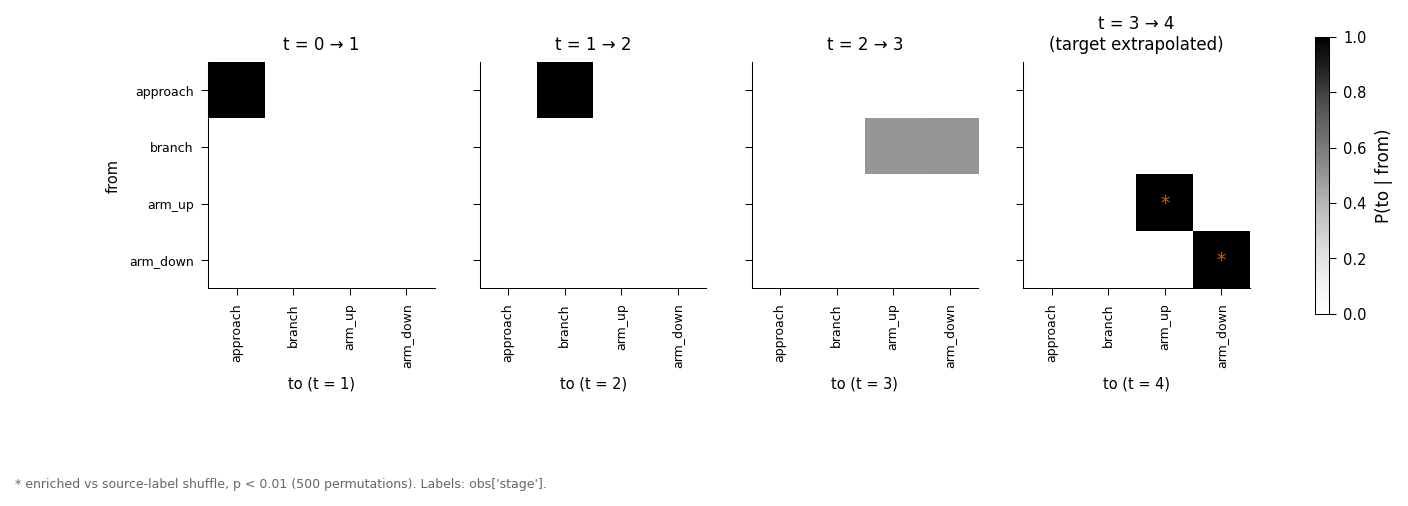

In [8]:
fig = figure_flow_transitions(adata); plt.show()

The same with the archetype labels (the default). `prob` gives the operator **sequence** A1 → A2 → A1: approaching the fork, cells take on the spreading shape A2 (`prob` 0.75 from day 0, 0.97 from day 1); at the branch point, A2 cells pass into the converging shape A1 of the arms (0.90).

The null asks a narrower question: does a cell's **own** label predict where it goes, beyond what the whole population does? From day 0, A1 cells move to A2 at the population rate (0.75 vs `expected_prob` 0.76): that is a population-wide shift, not specific to A1 cells. What is label-specific is that A2 cells stay A2 (0.99 vs 0.76, `p_enriched` 0.002). Read `prob` for the sequence and the null for label dependence. `to_extrapolated` marks transitions into the last time, whose operators come from the drift extrapolated there; every day-4 cell is A1, so the null has no spread there and `z` is NaN.

In [9]:
tab_a = sj.flow_transitions(adata, n_perm=500)
tab_a[["from_time", "to_time", "from_label", "to_label", "n_from", "prob", "expected_prob", "z", "p_enriched", "to_extrapolated"]].round(3)

,from_time,to_time,from_label,to_label,n_from,prob,expected_prob,z,p_enriched,to_extrapolated
0,0.0,1.0,A1,A1,387,0.248,0.240,4.235,0.002,False
1,0.0,1.0,A1,A2,387,0.752,0.760,-4.235,1.000,False
2,0.0,1.0,A2,A1,13,0.010,0.239,-4.235,1.000,False
3,0.0,1.0,A2,A2,13,0.990,0.761,4.235,0.002,False
4,1.0,2.0,A1,A1,96,0.027,0.008,12.636,0.002,False
5,1.0,2.0,A1,A2,96,0.973,0.992,-12.636,1.000,False
6,1.0,2.0,A2,A1,304,0.001,0.007,-12.636,1.000,False
7,1.0,2.0,A2,A2,304,0.999,0.993,12.636,0.002,False
8,2.0,3.0,A1,A1,3,0.975,0.898,1.774,0.040,False
9,2.0,3.0,A1,A2,3,0.025,0.102,-1.774,0.962,False


## 4. `sj.flow_paths`: chains through the plan

Chains start at random first-time cells and step to a destination drawn from each cell's stored plan row. The label sequences are counted and compared with a Markov chain on the per-pair matrices of the same stored plan. `obs_over_expected` near 1 means the current label is enough to predict the next one; far from 1 points to memory or rare routes that the matrices average away. `collapse=True` merges repeats. Because the stored plan keeps only each cell's nearest destinations, path frequencies are approximate; the transition matrices are the exact readout.

In [10]:
sj.flow_paths(adata, labels="stage", n_paths=5000, collapse=True).round(3)

,path,count,frequency,expected,obs_over_expected
0,approach > branch > arm_up,2548,0.51,0.495,1.030
1,approach > branch > arm_down,2452,0.49,0.505,0.971


## 5. `sj.flow_integrate`: drift paths, for pictures

Integrates $\dot z = f(z)$ from chosen cells with the stored drift (rebuilt by `scjdo2.flow_operator.load_drift`), and returns $\lambda_1$ and the archetype weights along each path. Each path picks one arm and $\lambda_1$ peaks as it crosses the fork. A deterministic path cannot branch, so use this to illustrate, not to test.

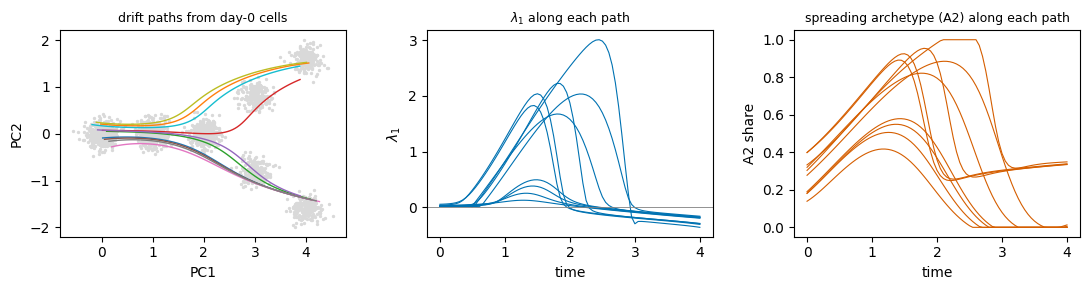

In [11]:
start = np.flatnonzero(adata.obs["day"].to_numpy() == 0)[:10]
res = sj.flow_integrate(adata, start, n_steps=80)
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
axs[0].scatter(*adata.obsm["X_pca"][:, :2].T, s=2, c="0.85")
for p in res["z"]:
    axs[0].plot(p[:, 0], p[:, 1], lw=1)
axs[0].set_xlabel("PC1"); axs[0].set_ylabel("PC2"); axs[0].set_title("drift paths from day-0 cells", fontsize=9)
axs[1].plot(res["t"], res["lambda1"].T, lw=0.8, color="#0072b2"); axs[1].axhline(0, color="0.5", lw=0.6)
axs[1].set_xlabel("time"); axs[1].set_ylabel(r"$\lambda_1$"); axs[1].set_title(r"$\lambda_1$ along each path", fontsize=9)
w = res["archetype_weights"]; share = w[..., 1] / np.maximum(w.sum(-1), 1e-12)
axs[2].plot(res["t"], share.T, lw=0.8, color="#d55e00")
axs[2].set_xlabel("time"); axs[2].set_ylabel("A2 share"); axs[2].set_title("spreading archetype (A2) along each path", fontsize=9)
plt.tight_layout(); plt.show()

## In one call, and what to check

`sj.run(adata, "runs/x", cluster_key="cell_type", time_key="day", motifs=True)` runs `flow` → `flow_groups` → `flow_archetypes` → `flow_transitions` (by archetype and by `cluster_key`) and saves `transitions.csv`, `transitions_by_cluster.csv`, the figures and the AnnData (reload with `scjdo2.io.load`). `sj.figures` draws `flow_archetypes` and `flow_transitions` whenever their inputs exist.

Before reading a motif on real data:
* **Refits.** Archetype labels inherit the fit-to-fit variation of $J$ (per-cell $\lambda_1$ ranks agreed only ~0.56 across seeds in the App Note's tests). Refit with other seeds and compare labels.
* **Replicates.** Whether archetype shapes are stable across biological replicates is untested.
* **Balanced transport.** Changes in composition between times are moved as state changes; proliferation and death are not modelled.
* **Last time point.** Its operators are extrapolated (`to_extrapolated`).